In [1]:
import matplotlib.pyplot as plt
import pandas as pd


In [2]:
data_root = "../../tasks/lab1/dataset/lab1-01.csv"
data = pd.read_csv(data_root, header=None)

In [3]:
data.head(5)

,0,1
0,1.040404,-205.789979
1,4.555556,-1933.310618
2,2.414141,-1075.586885
3,3.101010,-889.283808
4,1.929293,114.306301


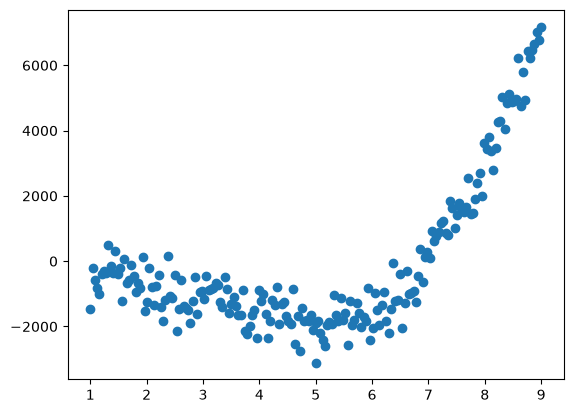

In [4]:
plt.scatter(data[0], data[1])

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [6]:
x_train, x_test, y_train, y_test = train_test_split(data[0].to_frame(), data[1], test_size=0.2)

In [7]:
model = LinearRegression()

In [8]:
model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[671.87]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-3491
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[28.92]


In [9]:
y_test_pred = model.predict(x_test)

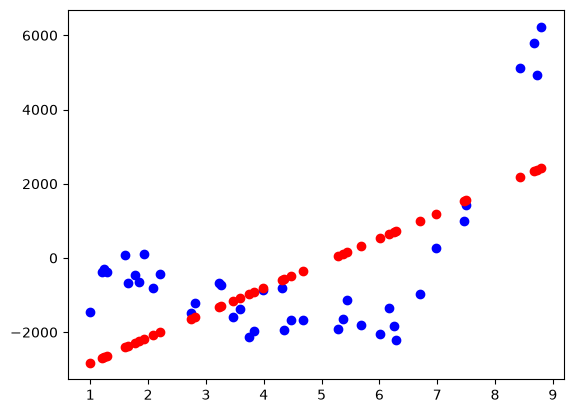

In [10]:
plt.scatter(x_test, y_test, color='blue')
plt.scatter(x_test, y_test_pred, color='red')

In [11]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [12]:
mae = mean_absolute_error(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
print(mae, mse)

1588.2142992738522 3426140.384251532


Как видим, не только по метрикам, но в первую очередь визуально, модель не смогла обобщить данные

In [13]:
x_train2 = x_train
x_train2[1] = x_train[0] * x_train[0]

In [14]:
x_train2.head(5)

,0,1
144,8.030303,64.485767
5,4.595960,21.122845
159,5.767677,33.266095
136,4.393939,19.306703
126,2.616162,6.844302


In [15]:
model2 = LinearRegression()
model2.fit(x_train2, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[-2798.95, 342.48]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3510
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](2,)","[300.38, 5.71]"


In [16]:
x_test2 = x_test.copy()
x_test2[1] = x_test2[0] * x_test2[0]

In [17]:
y_test_pred2 = model2.predict(x_test2)

In [18]:
x_test.shape

(40, 1)

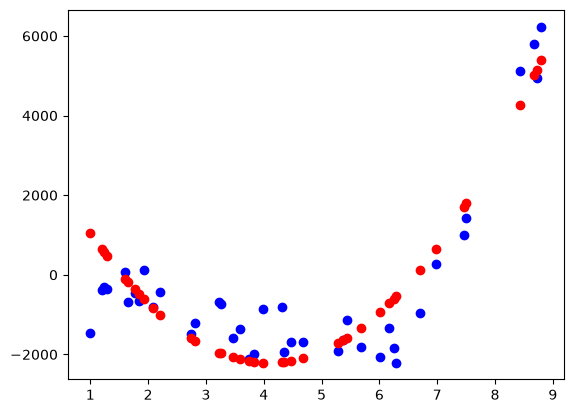

In [19]:
plt.scatter(x_test, y_test, color='blue')
plt.scatter(x_test[0], y_test_pred2, color='red')

In [ ]:

y_train_pred2 = model2.predict(x_train2)
mae_test = mean_absolute_error(y_test, y_test_pred2)
mse_test = mean_squared_error(y_test, y_test_pred2)
print(mae_test, mse_test)

mae_train = mean_absolute_error(y_train, y_train_pred2)
mse_train = mean_squared_error(y_train, y_train_pred2)
print(mae_train, mse_train)

672.9083276978512 720615.9744573551
605.4622530583541 555056.0698693577


Так как зависимость, которую необходимо было регрессировать, не является линейной, то обычная линейная модель не может выучить такую зависимость. Чтобы это исправить, был добавлен новый признак x^2, что позволило модели находить нелинейные зависимости в данных